Slope: 9.000000000000004
Intercept: 30.99999999999999
R-squared: 0.9759036144578314
R-squared percentage: 97.59036144578313 %
rmse: 2.0
Predicted Marks: 85.00000000000001


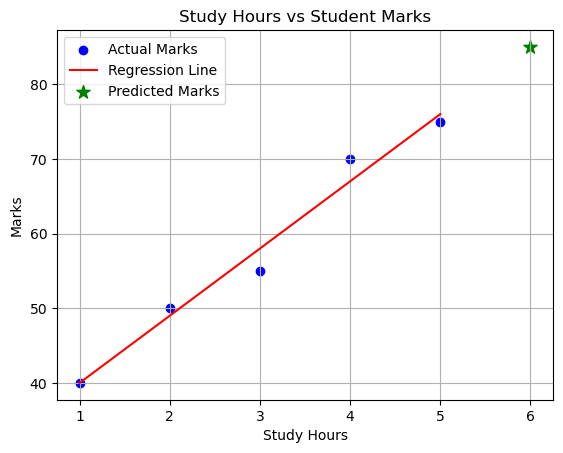

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Input data: Study Hours
X = np.array([1, 2, 3, 4, 5]).reshape(-1, 1)

# Output data: Marks
y = np.array([40, 50, 55, 70, 75])

# Create the model
model = LinearRegression()

# Train the model
model.fit(X, y)

# Display slope and intercept
y_pred=model.predict(X)
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)
from sklearn.metrics import r2_score,mean_squared_error
r2=r2_score(y,y_pred)
mse=mean_squared_error(y,y_pred)
rmse=np.sqrt(mse)
print("R-squared:",r2)
print("R-squared percentage:",r2*100,"%")
print("rmse:",rmse)

# Predict marks for 6 study hours
prediction = model.predict([[6]])

print("Predicted Marks:", prediction[0])

# Draw actual data points
plt.scatter(X, y, color="blue", label="Actual Marks")

# Draw regression line
plt.plot(
    X,
    model.predict(X),
    color="red",
    label="Regression Line"
)

# Display predicted point
plt.scatter(
    6,
    prediction[0],
    color="green",
    s=100,
    marker="*",
    label="Predicted Marks"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Student Marks")
plt.legend()
plt.grid(True)
plt.show()


In [9]:
import pandas as pd

data={"StudyHours":[1,2,3,4,5],"Attendence":[40,20,60,100,80],"Marks":[18,17,25,33,32]}
df=pd.DataFrame(data)
new_student=pd.DataFrame({"StudyHours":[6],"Attendence":[90]})
X=df[["StudyHours","Attendence"]]
y=df["Marks"]
print(new_student)
model.fit(X,y)
print(model.coef_[1])

   StudyHours  Attendence
0           6          90
0.14999999999999997


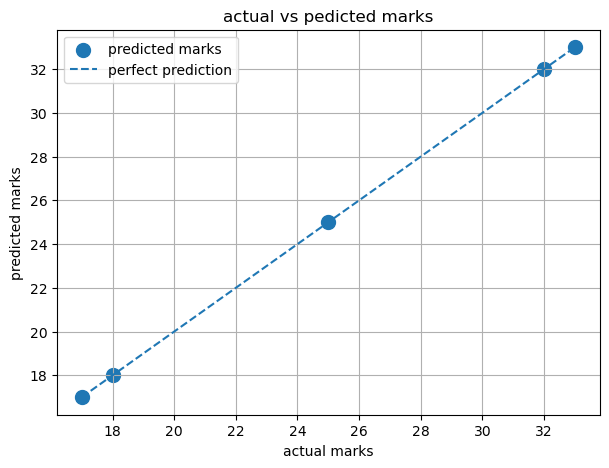

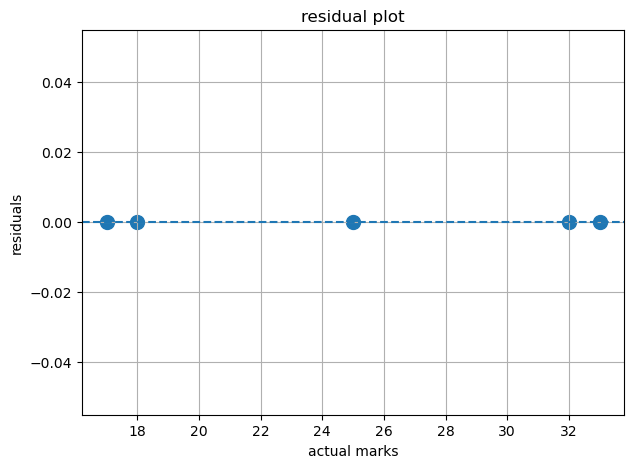

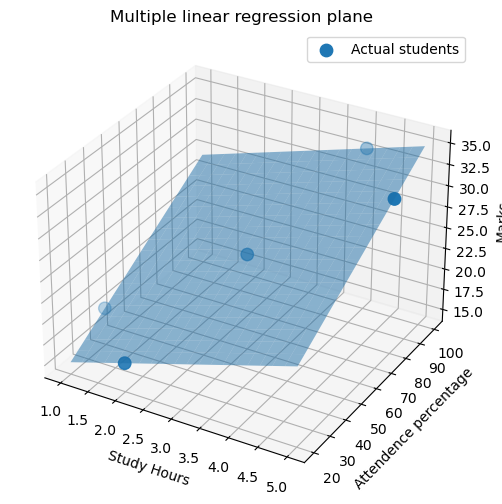

In [14]:
y_pred=model.predict(X)
df["PredictedMarks"]=y_pred
plt.figure(figsize=(7,5))
plt.scatter(y,y_pred,s=100,label="predicted marks")
plt.plot([y.min(),y.max()],[y.min(),y.max()],linestyle="--",label="perfect prediction")
plt.xlabel("actual marks")
plt.ylabel("predicted marks")
plt.title("actual vs pedicted marks")
plt.legend()
plt.grid()
plt.show()
residuals=y-y_pred
plt.figure(figsize=(7,5))
plt.scatter(y_pred,residuals,s=100)
plt.axhline(y=0,linestyle="--")
plt.xlabel("actual marks")
plt.ylabel("residuals")
plt.title("residual plot")

plt.grid()
plt.show()
fig=plt.figure(figsize=(9,6))
ax=fig.add_subplot(111,projection="3d")
study_range=np.linspace(1,5,20)
attendence_range=np.linspace(20,100,20)
study_grid,attendence_grid=np.meshgrid(study_range,attendence_range)
plane_input=pd.DataFrame({"StudyHours":study_grid.ravel(),"Attendence":attendence_grid.ravel()})
marks_grid=model.predict(plane_input).reshape(study_grid.shape)
ax.plot_surface(study_grid,attendence_grid,marks_grid,alpha=0.5)
ax.scatter(df["StudyHours"],df["Attendence"],df["Marks"],s=80,label="Actual students")
ax.set_xlabel("Study Hours")
ax.set_ylabel("Attendence percentage")
ax.set_zlabel("Marks")
ax.set_title("Multiple linear regression plane")
ax.legend()
plt.show()